# 04 · Do some contracting offices run hotter than others? Mixed-effects models

DOT awards are written by ~70 contracting offices. Offices differ in workload, staff and the kind of work they
buy, so awards from the same office are not independent. Ignoring that clustering understates standard errors.
Treating each office as a fixed dummy overfits the small ones.

A **mixed-effects model** gives each office a random intercept drawn from a common distribution. Small offices
get *shrunk* toward the overall mean in proportion to how little data they have.

1. Linear mixed model (LMM) on log excess growth for awards that grew (the severity part from notebook 03):
   random intercept by office, then a random slope for cost-type pricing, compared by likelihood ratio.
2. Intra-class correlation: what share of the unexplained variance sits between offices?
3. Shrinkage: raw office means vs. model estimates (BLUPs).
4. A binomial GLMM for the hurdle (does the award grow at all?), fitted by variational Bayes.

In [1]:
import sys; sys.path.append("..")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
from src.features import RHS, load_awards, model_frame

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
df = model_frame(load_awards())
cap = df["growth_ratio"].quantile(0.995)
df["log_excess"] = np.log(df["growth_ratio"].clip(upper=cap) - 1).where(df["any_growth"] == 1)
df["cost_type"] = df["pricing"].isin(["cost_reimbursement", "time_materials"]).astype(int)

grew = df[df["any_growth"] == 1].copy()
# Offices with fewer than 20 grown awards carry almost no information about their own intercept; pool them.
small = grew["office"].map(grew["office"].value_counts()) < 20
grew.loc[small, "office"] = "pooled_small"
print(f"{len(grew):,} awards that grew, {grew['office'].nunique()} office groups")

# Fixed part: the shared RHS without sub-agency, which is nested above office and would compete with it.
fixed = RHS.replace(" + C(sub_agency, Treatment('FAA'))", "")

16,512 awards that grew, 59 office groups


## 1. Random intercept vs random intercept + slope

Fit by maximum likelihood (not REML) so the log-likelihoods of models with the same fixed part can be compared
with a likelihood ratio test. Powell is used because the default gradient optimizer (L-BFGS) diverged on this
data and stopped at τ² = 0; Powell and Nelder-Mead both converge to the same non-zero optimum.

In [2]:
m0 = smf.ols("log_excess ~ " + fixed, grew).fit()
m1 = smf.mixedlm("log_excess ~ " + fixed, grew, groups=grew["office"]).fit(reml=False, method="powell")
m2 = smf.mixedlm("log_excess ~ " + fixed, grew, groups=grew["office"], re_formula="~cost_type").fit(
    reml=False, method="powell")

def lr_test(small, big, df_diff, boundary=True):
    stat = 2 * (big.llf - small.llf)
    # Testing a variance at zero: the null distribution is a mixture, so halve the χ² p-value (conservative).
    p = stats.chi2.sf(stat, df_diff) * (0.5 if boundary else 1)
    return stat, p

s01, p01 = lr_test(m0, m1, 1)
s12, p12 = lr_test(m1, m2, 2)
print(f"office random intercept vs none: LR = {s01:.1f}, p = {p01:.2g}")
print(f"+ random slope for cost-type pricing: LR = {s12:.1f}, p = {p12:.2g}")

office random intercept vs none: LR = 1176.1, p = 4.7e-258
+ random slope for cost-type pricing: LR = 178.0, p = 1.1e-39


## 2. How much variation sits between offices?

In [3]:
tau2 = m1.cov_re.iloc[0, 0]
sigma2 = m1.scale
print(f"between-office variance τ² = {tau2:.3f}, residual σ² = {sigma2:.3f}")
print(f"ICC = {tau2 / (tau2 + sigma2):.3f}")
print(f"An office one SD above average has {np.exp(np.sqrt(tau2)) - 1:.0%} more excess growth on grown awards, "
      "holding contract features fixed.")
if p12 < 0.05:
    print("\nRandom-effects covariance with slope (intercept, cost_type):")
    print(m2.cov_re.round(3))

between-office variance τ² = 0.274, residual σ² = 2.801
ICC = 0.089
An office one SD above average has 69% more excess growth on grown awards, holding contract features fixed.

Random-effects covariance with slope (intercept, cost_type):
           Group  cost_type
Group      0.362     -0.187
cost_type -0.187      0.404


## 3. Shrinkage

Each office's raw mean residual (from the OLS fit without office effects) vs its estimated random intercept
(BLUP). Small offices are pulled hard toward zero; large ones keep almost their raw value. This is why a mixed
model is a better basis for ranking offices than raw averages.

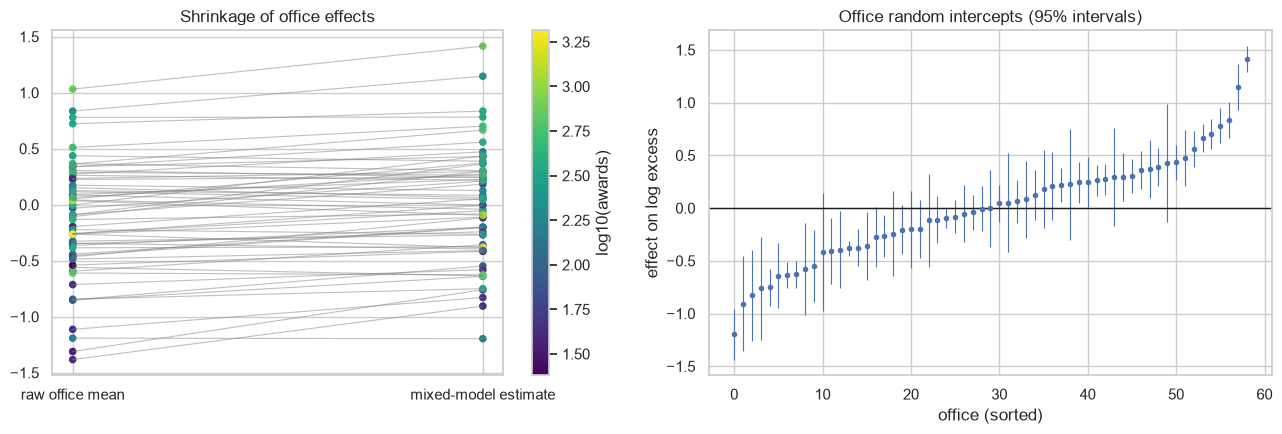

In [4]:
re = pd.Series({k: v.iloc[0] for k, v in m1.random_effects.items()}, name="blup")
raw = m0.resid.groupby(grew["office"]).mean().rename("raw_mean_residual")
n = grew["office"].value_counts().rename("n")
shr = pd.concat([raw, re, n], axis=1).dropna()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for _, r in shr.iterrows():
    ax[0].plot([0, 1], [r["raw_mean_residual"], r["blup"]], color="grey", alpha=0.5, lw=0.8)
sc = ax[0].scatter(np.zeros(len(shr)), shr["raw_mean_residual"], c=np.log10(shr["n"]), cmap="viridis", s=20)
ax[0].scatter(np.ones(len(shr)), shr["blup"], c=np.log10(shr["n"]), cmap="viridis", s=20)
ax[0].set_xticks([0, 1], ["raw office mean", "mixed-model estimate"])
ax[0].set_title("Shrinkage of office effects"); plt.colorbar(sc, ax=ax[0], label="log10(awards)")

# Caterpillar plot with approximate 95% intervals from the conditional variances.
cond_var = pd.Series({k: v.iloc[0, 0] for k, v in m1.random_effects_cov.items()})
cat = shr.assign(se=np.sqrt(cond_var.reindex(shr.index))).sort_values("blup")
ax[1].errorbar(np.arange(len(cat)), cat["blup"], yerr=1.96 * cat["se"], fmt="o", ms=3, lw=0.8)
ax[1].axhline(0, color="k", lw=1)
ax[1].set(title="Office random intercepts (95% intervals)", xlabel="office (sorted)", ylabel="effect on log excess")
plt.tight_layout(); plt.savefig(FIG + "04_office_shrinkage.png", dpi=120); plt.show()

In [5]:
names = df.groupby("office")["awarding_office_name"].first()
top = cat.assign(office_name=names.reindex(cat.index)).sort_values("blup")
pd.concat([top.head(5), top.tail(5)])[["office_name", "n", "raw_mean_residual", "blup", "se"]].round(3)

,office_name,n,raw_mean_residual,blup,se
6913G6,6913G6 VOLPE NATL. TRANS. SYS CNTR,176,-1.191,-1.196,0.123
00075,ACQUISITION MANAGEMENT DIVISION,43,-1.383,-0.905,0.229
00057,DOT-OR&T 00057,47,-1.113,-0.829,0.221
00055,DEPT OF TRANS/SLSDC,35,-1.311,-0.759,0.249
00061,OFFICE OF ACQUISITION AND GRANTS MANAGEMENT,341,-0.843,-0.750,0.089
6933A2,6933A2 DOT MARITIME ADMINISTRATION,533,0.511,0.701,0.072
693JF7,693JF7 DOT MARITIME ADMINISTRATION,367,0.779,0.782,0.086
693JF9,693JF9 HEADQUARTERS,345,0.723,0.835,0.089
00003,DEPT OF TRANS/FEDERAL AVIATION ADMIN,212,0.836,1.147,0.112
00001,DEPT OF TRANS/FEDERAL AVIATION ADMIN,732,1.032,1.415,0.061


## 4. Do the fixed effects change once offices are accounted for?

If a contract feature looked important only because certain offices both use it and see high growth, its
coefficient will move between OLS and the mixed model.

In [6]:
keys = [k for k in m1.fe_params.index if any(s in k for s in ["pricing", "single_offer", "september", "final_two", "competition"])]
cmp = pd.DataFrame({"OLS": m0.params[keys], "OLS SE": m0.bse[keys],
                    "mixed": m1.fe_params[keys], "mixed SE": m1.bse_fe[keys]})
cmp.round(3)

,OLS,OLS SE,mixed,mixed SE
"C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]",0.196,0.048,0.088,0.052
"C(pricing, Treatment('firm_fixed'))[T.fixed_other]",0.265,0.182,0.322,0.177
"C(pricing, Treatment('firm_fixed'))[T.time_materials]",0.299,0.045,0.223,0.046
"C(competition, Treatment('full_open'))[T.not_competed]",0.207,0.047,0.048,0.046
"C(competition, Treatment('full_open'))[T.other]",-0.123,0.874,-0.101,0.840
"C(competition, Treatment('full_open'))[T.set_aside]",-0.227,0.045,-0.176,0.044
"C(competition, Treatment('full_open'))[T.simplified]",-0.205,0.055,-0.339,0.053
single_offer,0.037,0.053,0.188,0.053
september,-0.215,0.052,-0.184,0.051
final_two_weeks,0.062,0.063,0.045,0.061


## 5. Binomial GLMM for the hurdle

Same idea for the probability that an award grows at all, using all 60k awards. statsmodels fits binomial GLMMs by
variational Bayes. The random-effect SD is on the log-odds scale.

In [7]:
allaw = df.copy()
small_all = allaw["office"].map(allaw["office"].value_counts()) < 20
allaw.loc[small_all, "office"] = "pooled_small"
glmm = BinomialBayesMixedGLM.from_formula("any_growth ~ " + fixed, {"office": "0 + C(office)"}, allaw).fit_vb()
sd_office = np.exp(glmm.vcp_mean[0])
print(f"office SD on the log-odds scale ≈ {sd_office:.2f}")
print(f"Between a typical office at −1 SD and +1 SD, the odds of growth differ by a factor of {np.exp(2 * sd_office):.1f}")
# Latent-variable ICC for a logit model: τ² / (τ² + π²/3)
print(f"latent ICC ≈ {sd_office**2 / (sd_office**2 + np.pi**2 / 3):.3f}")

office SD on the log-odds scale ≈ 0.55
Between a typical office at −1 SD and +1 SD, the odds of growth differ by a factor of 3.0
latent ICC ≈ 0.084


## Findings

- **Offices matter.** The office random intercept improves the fit enormously (LR ≈ 1,176). About 9% of the
  unexplained variance in (log) excess growth sits between offices. An office one SD above average sees ~70% more
  excess growth on comparable awards. The binomial GLMM gives the same ICC (~0.08) for the *probability* of
  growth: ±1 SD of office spans a 3× difference in odds.
- **Offices also differ in how cost-type pricing plays out** (random slope, LR p ≈ 1e-39). The negative
  intercept-slope covariance means offices with high baseline growth see *less* extra growth from cost-type
  pricing, and vice versa.
- **Some "contract design" effects were partly office effects.** After adjusting for office, the
  cost-reimbursement coefficient halves (0.20 → 0.09) and the not-competed coefficient nearly vanishes
  (0.21 → 0.05). Offices that use these arrangements more also run hotter. Time-and-materials (0.30 → 0.22) and
  the September discount (−0.22 → −0.18) survive. Single-offer awards become *more* clearly associated with
  growth (0.04 → 0.19) once compared within the same office.
- **Shrinkage does its job.** Offices with a few dozen awards are pulled toward zero. Large offices keep their
  raw estimates. Rankings built on raw averages would put small, noisy offices at both extremes.
- **Caveat:** FPDS office codes changed around FY2016 (legacy 5-digit codes → `69xxxx` codes), so one physical
  office can appear under two codes. The model treats them as separate groups. That inflates the group count
  but does not bias the fixed effects.